### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

### **1. Linear Regression**

**Linear Regression** predicts a **continuous value** by fitting the best line (or hyperplane) to the data.

* **Simple:** $y = \beta_0 + \beta_1 x + \epsilon$
* **Multiple:** $y = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n + \epsilon$

$\beta_0$ is the **intercept**, $\beta_i$ the **coefficients** and $\epsilon$ the **noise**. The algorithm learns the $\beta$ that minimise the **sum of squared errors**.

In [3]:
#Generate a Synthetic Dataset ( y = 2x + 1 + noise )
rng = np.random.default_rng(RANDOM_STATE)
X_lin = rng.uniform(0, 10, 100).reshape(-1, 1)
y_lin = 2 * X_lin.ravel() + 1 + rng.normal(0, 2, 100)

df_lin = pd.DataFrame({"X": X_lin.ravel(), "y": y_lin})
df_lin.head()

,X,y
0,7.740,17.279
1,4.389,7.967
2,8.586,17.416
3,6.974,17.546
4,0.942,2.171


learned : y = 2.02 x + 0.90
true    : y = 2.00 x + 1.00


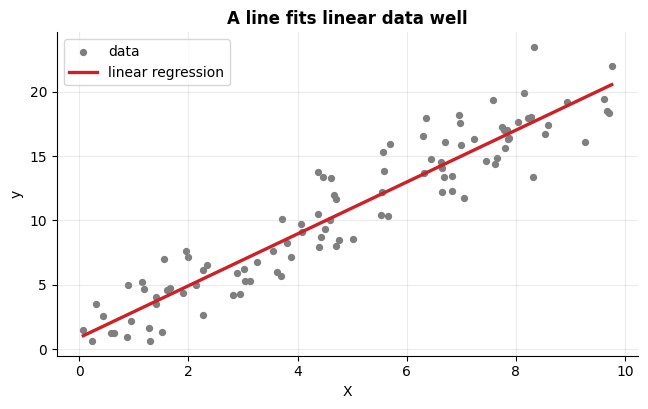

In [4]:
#Fit a Linear Regression and Plot the Line
from sklearn.linear_model import LinearRegression

lin = LinearRegression().fit(X_lin, y_lin)
print(f"learned : y = {lin.coef_[0]:.2f} x + {lin.intercept_:.2f}")
print("true    : y = 2.00 x + 1.00")

x_line = np.sort(X_lin, axis=0)
plt.figure()
plt.scatter(X_lin, y_lin, s=18, color=GRAY, label="data")
plt.plot(x_line, lin.predict(x_line), color=RED, lw=2.4, label="linear regression")
plt.xlabel("X"); plt.ylabel("y"); plt.legend()
plt.title("A line fits linear data well")
plt.show()

The data are **linear**, so the line is a **good fit** – this is *not* underfitting. Underfitting appears when the model is too simple **for the pattern** in the data (section 3).

### **2. Generalization: Training × Test Error**

A model must perform well on data it **has not seen**. We compare the error on the **training** and on the **test** data:

| | Training error | Test error |
|---|---|---|
| **Underfitting** (high bias) | **high** | **high** |
| **Good fit** | low | low (close to training) |
| **Overfitting** (high variance) | **very low** | **much higher** |

In [5]:
#Training and Test Error of the Linear Model ( Good Generalization )
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X_a, X_b, y_a, y_b = train_test_split(X_lin, y_lin, test_size=0.3, random_state=RANDOM_STATE)
m = LinearRegression().fit(X_a, y_a)

pd.DataFrame({"MSE": [mean_squared_error(y_a, m.predict(X_a)), mean_squared_error(y_b, m.predict(X_b))],
              "R²":  [r2_score(y_a, m.predict(X_a)), r2_score(y_b, m.predict(X_b))]},
             index=["training", "test"])

,MSE,R²
training,4.021,0.887
test,3.560,0.880


The two errors are **close** and near the noise variance ($2^2 = 4$): the model **generalises**.

### **3. Underfitting**

The model is **too simple** to capture the pattern (**high bias**).

* **Low performance** on training **and** test data
* It misses the real relationship: it needs **more flexibility** or **better attributes**

Now the data follow a **curve**: $y = \sin(2\pi x) + \epsilon$

In [6]:
#Generate Non-linear Data ( y = sin(2πx) + noise )
def true_function(x):
    return np.sin(2 * np.pi * x)

def make_data(n, noise=0.3, seed=0):
    rng = np.random.default_rng(seed)
    x = rng.random(n)
    return x.reshape(-1, 1), true_function(x) + rng.normal(0, noise, n)

X_tr, y_tr = make_data(30, seed=58)           # small training set (a typical draw – see section 4)
X_te, y_te = make_data(300, seed=99999)       # large, independent test set
grid = np.linspace(0, 1, 300).reshape(-1, 1)

pd.DataFrame({"X": X_tr.ravel(), "y": y_tr}).head()

,X,y
0,0.309,1.162
1,0.880,-0.650
2,0.243,0.910
3,0.208,1.183
4,0.846,-1.005


In [7]:
#Helper Functions: Polynomial Model and Training / Test Errors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

def poly_model(degree, reg=None):
    reg = LinearRegression() if reg is None else reg
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), reg)

def errors(model):
    return mean_squared_error(y_tr, model.predict(X_tr)), mean_squared_error(y_te, model.predict(X_te))

training MSE = 0.280 | test MSE = 0.314 | noise variance = 0.09


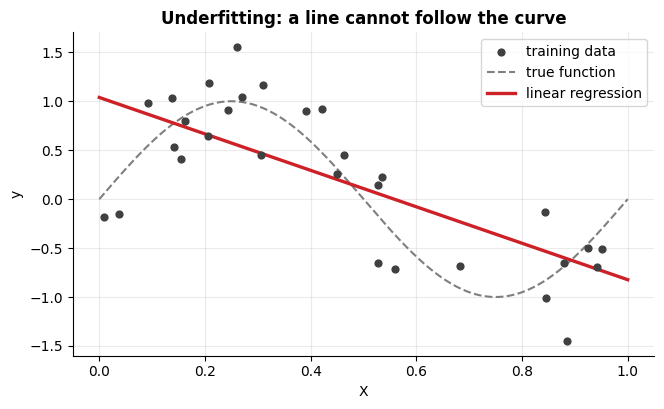

In [8]:
#Fit a Straight Line to the Curved Data ( Underfitting )
line = poly_model(1).fit(X_tr, y_tr)
e_tr, e_te = errors(line)
print(f"training MSE = {e_tr:.3f} | test MSE = {e_te:.3f} | noise variance = {0.3**2:.2f}")

plt.figure()
plt.scatter(X_tr, y_tr, s=24, color=DARK, zorder=3, label="training data")
plt.plot(grid, true_function(grid), color=GRAY, ls="--", label="true function")
plt.plot(grid, line.predict(grid), color=RED, lw=2.4, label="linear regression")
plt.xlabel("X"); plt.ylabel("y"); plt.legend()
plt.title("Underfitting: a line cannot follow the curve")
plt.show()

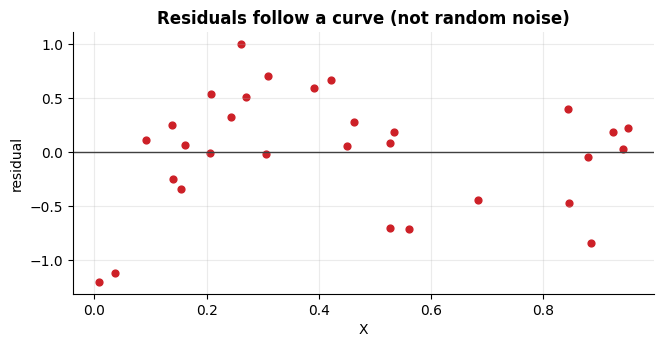

In [9]:
#Residuals Reveal the Missed Pattern
residuals = y_tr - line.predict(X_tr)

plt.figure(figsize=(7.5, 3.4))
plt.scatter(X_tr, residuals, s=24, color=RED)
plt.axhline(0, color=DARK, lw=1)
plt.xlabel("X"); plt.ylabel("residual")
plt.title("Residuals follow a curve (not random noise)")
plt.show()

With a good fit the residuals scatter **randomly** around zero. Here they follow a **pattern**: the model left structure unexplained.

### **4. Overfitting**

The model is **too complex**: it fits the pattern **and the noise** of the training data (**high variance**).

* **Almost perfect** on training data, **poor** on new data
* It **memorises** the points and behaves erratically between and beyond them

training MSE = 0.077 | test MSE = 65.637


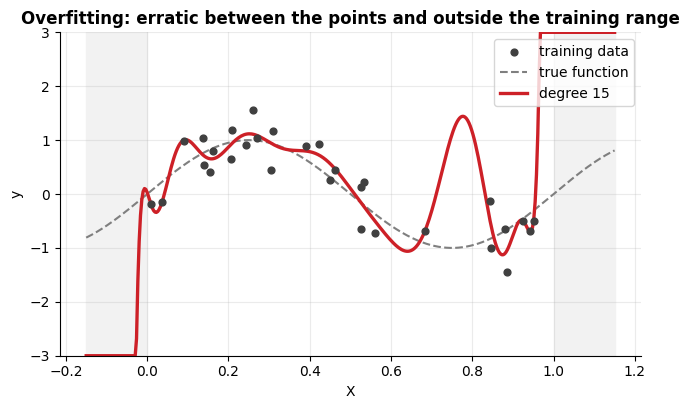

In [10]:
#Fit a Degree-15 Polynomial ( Too Complex for 30 Points )
over = poly_model(15).fit(X_tr, y_tr)
e_tr, e_te = errors(over)
print(f"training MSE = {e_tr:.3f} | test MSE = {e_te:.3f}")

wide = np.linspace(-0.15, 1.15, 400).reshape(-1, 1)
fig, ax = plt.subplots()
ax.axvspan(-0.15, 0, color="#F2F2F2"); ax.axvspan(1, 1.15, color="#F2F2F2")
ax.scatter(X_tr, y_tr, s=24, color=DARK, zorder=3, label="training data")
ax.plot(wide, true_function(wide), color=GRAY, ls="--", label="true function")
ax.plot(wide, np.clip(over.predict(wide), -3, 3), color=RED, lw=2.4, label="degree 15")
ax.set_ylim(-3, 3); ax.set_xlabel("X"); ax.set_ylabel("y"); ax.legend(loc="upper right")
ax.set_title("Overfitting: erratic between the points and outside the training range")
plt.show()

In [11]:
#Is This a Typical Case? ( 200 Different Training Sets )
rows = []
for s in range(200):
    Xs, ys = make_data(30, seed=s)
    rows.append({d: mean_squared_error(y_te, poly_model(d).fit(Xs, ys).predict(X_te)) for d in (1, 4, 15)})
draws = pd.DataFrame(rows)

display(draws.describe(percentiles=[0.5, 0.9]).loc[["50%", "90%"]]
        .rename(index={"50%": "median test MSE", "90%": "90th percentile"}, columns=lambda d: f"degree {d}").round(3))
print(f"degree 15 – test MSE of the training set used here: {e_te:.1f} | median over 200 draws: {draws[15].median():.1f}")

,degree 1,degree 4,degree 15
median test MSE,0.315,0.112,65.419
90th percentile,0.367,0.134,118468.956


degree 15 – test MSE of the training set used here: 65.6 | median over 200 draws: 65.4


A degree-15 fit is **unstable**: its test error depends on **which** 30 points are drawn, and the typical value is far above that of degree 4. The set used here is a **typical** draw.

### **5. Model Complexity**

The **degree** controls the flexibility. The training error always **falls**; the test error falls and then **rises**.

,degree,train MSE,test MSE
0,1,0.280,0.314
1,2,0.240,0.366
2,3,0.117,0.108
3,4,0.117,0.112
4,5,0.112,0.124
5,6,0.112,0.127
6,7,0.101,0.150
7,8,0.099,0.266
8,9,0.098,0.173
9,10,0.098,0.148


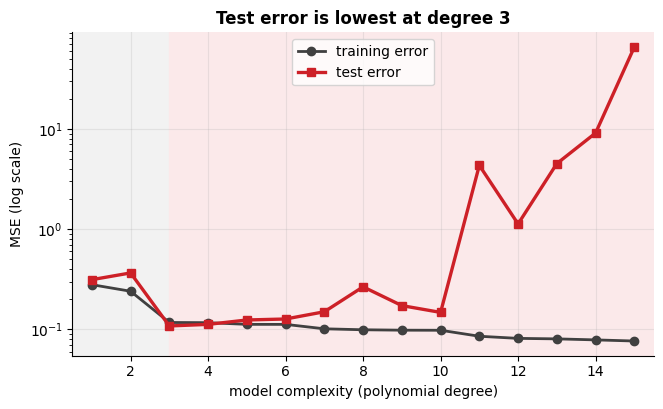

In [12]:
#Training and Test Error by Polynomial Degree
degrees = np.arange(1, 16)
rows = []
for d in degrees:
    rows.append((d, *errors(poly_model(d).fit(X_tr, y_tr))))
complexity = pd.DataFrame(rows, columns=["degree", "train MSE", "test MSE"])
display(complexity.round(3))

best = int(complexity.loc[complexity["test MSE"].idxmin(), "degree"])
plt.figure()
plt.plot(complexity["degree"], complexity["train MSE"], marker="o", color=DARK, lw=2, label="training error")
plt.plot(complexity["degree"], complexity["test MSE"], marker="s", color=RED, lw=2.4, label="test error")
plt.axvspan(0.5, best, color="#F2F2F2", zorder=0); plt.axvspan(best, 15.5, color="#FBE9EA", zorder=0)
plt.yscale("log"); plt.xlim(0.5, 15.5); plt.xlabel("model complexity (polynomial degree)"); plt.ylabel("MSE (log scale)")
plt.legend(loc="upper center"); plt.title(f"Test error is lowest at degree {best}")
plt.show()

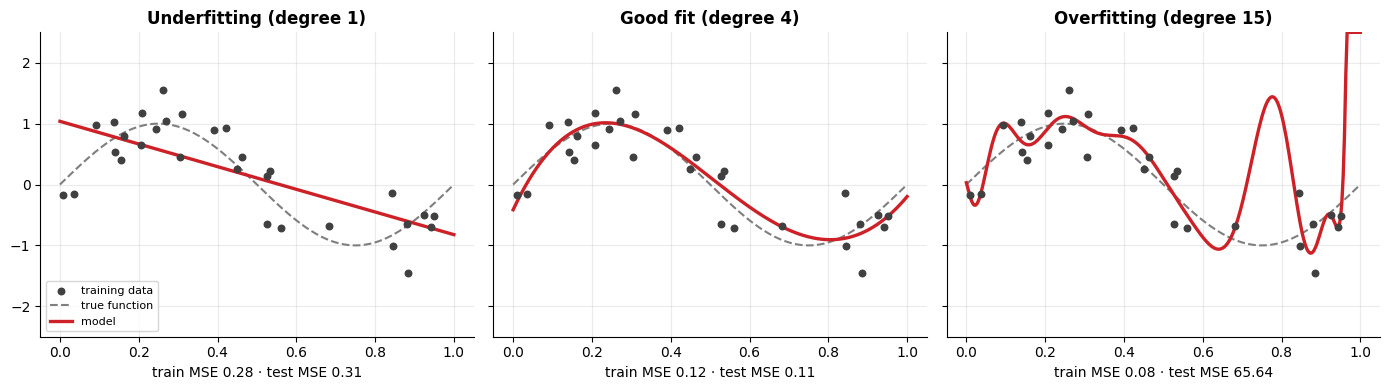

In [13]:
#Compare Underfitting, Good Fit and Overfitting
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, d, name in zip(axes, [1, 4, 15], ["Underfitting (degree 1)", "Good fit (degree 4)", "Overfitting (degree 15)"]):
    m = poly_model(d).fit(X_tr, y_tr)
    e_tr, e_te = errors(m)
    ax.scatter(X_tr, y_tr, s=22, color=DARK, zorder=3, label="training data")
    ax.plot(grid, true_function(grid), color=GRAY, ls="--", label="true function")
    ax.plot(grid, np.clip(m.predict(grid), -2.5, 2.5), color=RED, lw=2.4, label="model")
    ax.set_title(name); ax.set_ylim(-2.5, 2.5)
    ax.set_xlabel(f"train MSE {e_tr:.2f} · test MSE {e_te:.2f}")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

#### **Choosing the Complexity without the Test Set**

A **validation curve** estimates the error with **cross-validation** on the training data only.

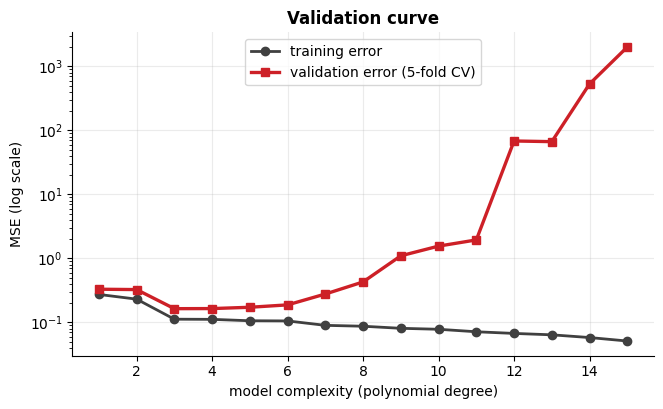

best degree according to cross-validation: 3


In [14]:
#Validation Curve ( 5-Fold Cross-Validation on the Training Set )
from sklearn.model_selection import KFold, validation_curve

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_sc, val_sc = validation_curve(
    make_pipeline(PolynomialFeatures(include_bias=False), StandardScaler(), LinearRegression()),
    X_tr, y_tr, param_name="polynomialfeatures__degree", param_range=degrees,
    cv=cv, scoring="neg_mean_squared_error")
train_err, val_err = -train_sc.mean(axis=1), -val_sc.mean(axis=1)

plt.figure()
plt.plot(degrees, train_err, marker="o", color=DARK, lw=2, label="training error")
plt.plot(degrees, val_err, marker="s", color=RED, lw=2.4, label="validation error (5-fold CV)")
plt.yscale("log"); plt.xlabel("model complexity (polynomial degree)"); plt.ylabel("MSE (log scale)")
plt.legend(loc="upper center"); plt.title("Validation curve")
plt.show()
print("best degree according to cross-validation:", int(degrees[val_err.argmin()]))

### **6. Bias and Variance**

$$\text{Expected error} = \text{Bias}^2 + \text{Variance} + \sigma^2$$

* **Bias:** systematic error from **too-simple assumptions** → underfitting
* **Variance:** sensitivity to **which training set** was drawn → overfitting
* $\sigma^2$: **irreducible noise**

The centre is the true value; each dot is the prediction of a model trained on a different sample.

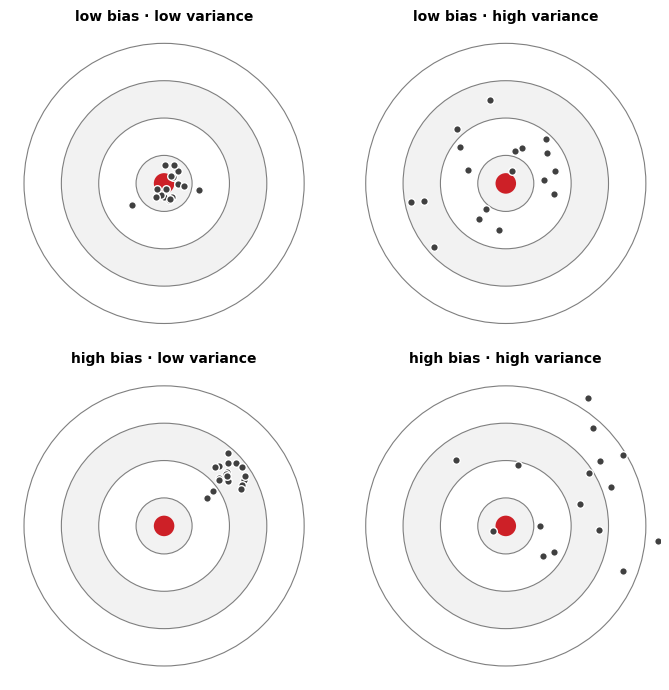

In [15]:
#The Dartboard: Bias and Variance
from matplotlib.patches import Circle

rng = np.random.default_rng(RANDOM_STATE)
cases = [("low bias · low variance", (0, 0), 0.35), ("low bias · high variance", (0, 0), 1.2),
         ("high bias · low variance", (1.5, 1.1), 0.35), ("high bias · high variance", (1.5, 1.1), 1.2)]
fig, axes = plt.subplots(2, 2, figsize=(7, 7))
for ax, (title, offset, spread) in zip(axes.ravel(), cases):
    for radius, color in zip([3, 2.2, 1.4, 0.6], ["white", "#F2F2F2", "white", "#F2F2F2"]):
        ax.add_patch(Circle((0, 0), radius, fc=color, ec=GRAY, lw=0.8))
    ax.add_patch(Circle((0, 0), 0.22, fc=RED))
    pts = rng.normal(offset, spread, (18, 2))
    ax.scatter(*pts.T, s=30, color=DARK, edgecolor="white", zorder=5)
    ax.set_xlim(-3.3, 3.3); ax.set_ylim(-3.3, 3.3); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

#### **Measuring Bias and Variance**

We train the same model on **300 different training sets** and compare the predictions on a fixed grid:

* $\text{bias}^2$ = mean of (average prediction − true value)²
* variance = mean variance of the predictions across training sets
* noise = $0.3^2 = 0.09$ (known, because we generated the data)

,degree,bias²,variance,noise,expected error
0,1,0.1764,0.0218,0.0900,0.2882
1,2,0.1752,0.0417,0.0900,0.3069
2,3,0.0034,0.0153,0.0900,0.1087
3,4,0.0035,0.0232,0.0900,0.1167
4,5,0.0001,0.0472,0.0900,0.1373
5,6,0.0018,0.1467,0.0900,0.2385
6,7,0.0036,0.3539,0.0900,0.4475
7,8,0.0133,3.3627,0.0900,3.4660


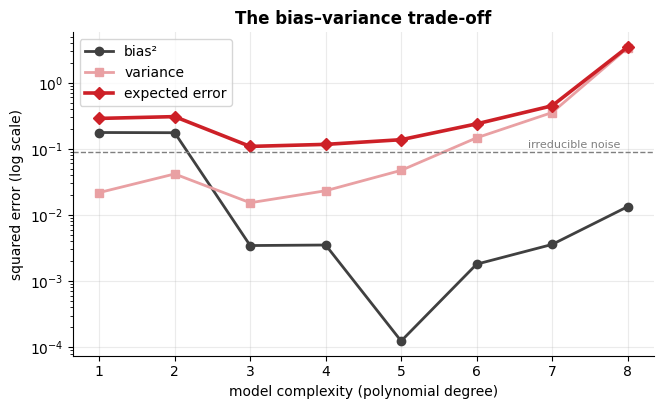

degree with the lowest expected error: 3


In [16]:
#Bias-Variance Decomposition by Simulation ( 300 Training Sets )
sim_degrees, n_sims, x_eval = range(1, 9), 300, np.linspace(0.02, 0.98, 100).reshape(-1, 1)

bias2, variance = [], []
for d in sim_degrees:
    preds = np.array([poly_model(d).fit(*make_data(30, seed=1000 + s)).predict(x_eval) for s in range(n_sims)])
    bias2.append(np.mean((preds.mean(axis=0) - true_function(x_eval.ravel())) ** 2))
    variance.append(np.mean(preds.var(axis=0)))

noise = 0.3 ** 2
decomp = pd.DataFrame({"degree": list(sim_degrees), "bias²": bias2, "variance": variance, "noise": noise})
decomp["expected error"] = decomp["bias²"] + decomp["variance"] + decomp["noise"]
with pd.option_context("display.float_format", "{:.4f}".format):
    display(decomp)

plt.figure()
plt.plot(decomp["degree"], decomp["bias²"], marker="o", color=DARK, lw=2, label="bias²")
plt.plot(decomp["degree"], decomp["variance"], marker="s", color=SOFT, lw=2, label="variance")
plt.plot(decomp["degree"], decomp["expected error"], marker="D", color=RED, lw=2.6, label="expected error")
plt.axhline(noise, color=GRAY, ls="--", lw=1); plt.text(7.9, noise * 1.15, "irreducible noise", ha="right", fontsize=8, color=GRAY)
plt.yscale("log"); plt.xlabel("model complexity (polynomial degree)"); plt.ylabel("squared error (log scale)")
plt.title("The bias–variance trade-off"); plt.legend(loc="upper left")
plt.show()
print("degree with the lowest expected error:", int(decomp.loc[decomp["expected error"].idxmin(), "degree"]))

As complexity grows, **bias falls** and **variance rises**. The best model sits at the **minimum of the total error** – we cannot zero both.

### **7. Learning Curves**

Error × **size of the training set**:

* **High bias:** both curves converge to a **high** error – more data will **not** help
* **High variance:** a **large gap** that shrinks as data grow – more data **do** help

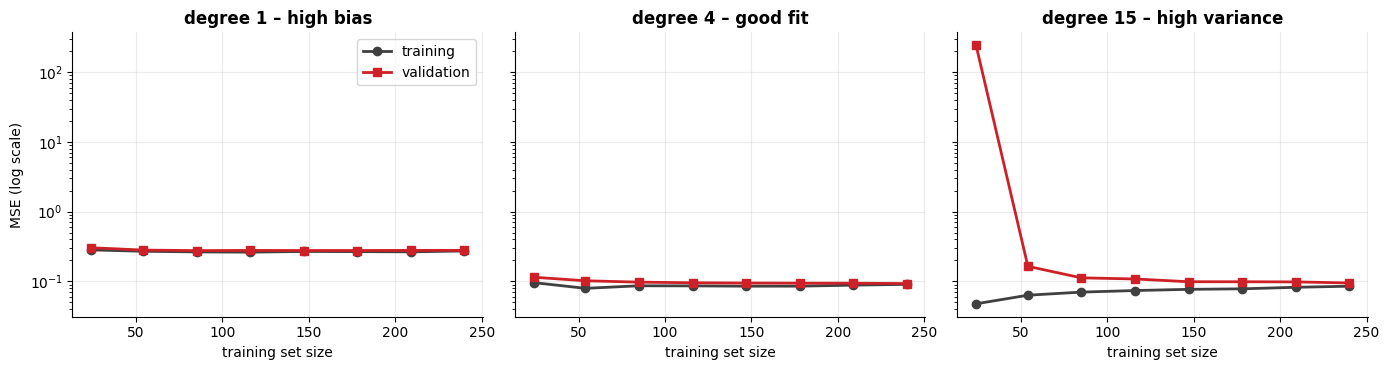

In [17]:
#Learning Curves for Degrees 1, 4 and 15
from sklearn.model_selection import learning_curve

X_big, y_big = make_data(300, seed=5)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, d, title in zip(axes, [1, 4, 15], ["degree 1 – high bias", "degree 4 – good fit", "degree 15 – high variance"]):
    sizes, tr, va = learning_curve(poly_model(d), X_big, y_big, train_sizes=np.linspace(0.1, 1.0, 8),
                                   cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="neg_mean_squared_error")
    ax.plot(sizes, -tr.mean(axis=1), marker="o", color=DARK, lw=2, label="training")
    ax.plot(sizes, -va.mean(axis=1), marker="s", color=RED, lw=2, label="validation")
    ax.set_yscale("log"); ax.set_title(title); ax.set_xlabel("training set size")
axes[0].set_ylabel("MSE (log scale)"); axes[0].legend()
plt.tight_layout(); plt.show()

### **8. Underfitting and Overfitting in Classification**

Same idea, different hyperparameters: **k** in k-NN and the **depth** of a decision tree.

* **k small / tree deep:** irregular boundary that follows every point → **overfitting**
* **k large / tree shallow:** overly smooth boundary → **underfitting**

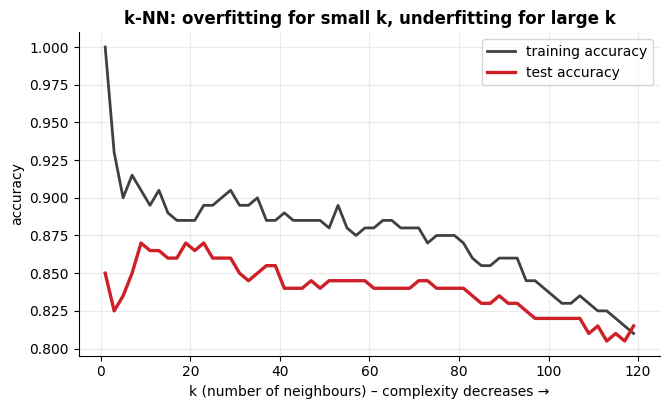

k = 1 → train 1.000, test 0.850 | best k = 9 (test 0.870)


In [18]:
#k-NN: Training × Test Accuracy by k
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

Xm, ym = make_moons(n_samples=400, noise=0.35, random_state=3)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.5, random_state=RANDOM_STATE, stratify=ym)

ks = list(range(1, 120, 2))
tr_acc, te_acc = [], []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k).fit(Xm_tr, ym_tr)
    tr_acc.append(knn.score(Xm_tr, ym_tr)); te_acc.append(knn.score(Xm_te, ym_te))

plt.figure()
plt.plot(ks, tr_acc, color=DARK, lw=2, label="training accuracy")
plt.plot(ks, te_acc, color=RED, lw=2.4, label="test accuracy")
plt.xlabel("k (number of neighbours) – complexity decreases →"); plt.ylabel("accuracy"); plt.legend()
plt.title("k-NN: overfitting for small k, underfitting for large k")
plt.show()
print(f"k = 1 → train {tr_acc[0]:.3f}, test {te_acc[0]:.3f} | best k = {ks[int(np.argmax(te_acc))]} (test {max(te_acc):.3f})")

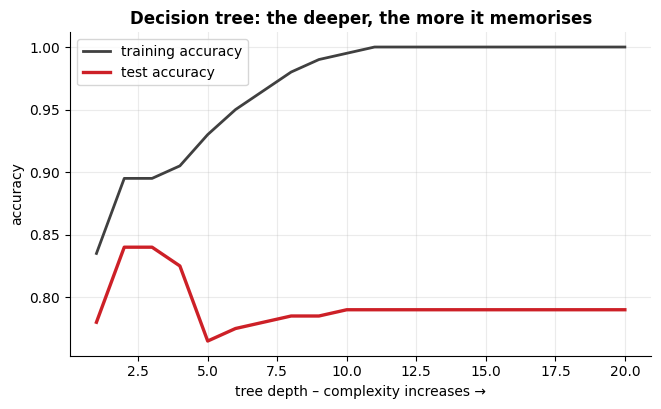

best depth = 2 (train 0.895, test 0.840) | depth 20 → train 1.000, test 0.790


In [19]:
#Decision Tree: Training × Test Accuracy by Depth
from sklearn.tree import DecisionTreeClassifier

depths = list(range(1, 21))
tr_acc_t, te_acc_t = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(Xm_tr, ym_tr)
    tr_acc_t.append(tree.score(Xm_tr, ym_tr)); te_acc_t.append(tree.score(Xm_te, ym_te))

plt.figure()
plt.plot(depths, tr_acc_t, color=DARK, lw=2, label="training accuracy")
plt.plot(depths, te_acc_t, color=RED, lw=2.4, label="test accuracy")
plt.xlabel("tree depth – complexity increases →"); plt.ylabel("accuracy"); plt.legend()
plt.title("Decision tree: the deeper, the more it memorises")
plt.show()
b = int(np.argmax(te_acc_t))
print(f"best depth = {depths[b]} (train {tr_acc_t[b]:.3f}, test {te_acc_t[b]:.3f}) | depth 20 → train {tr_acc_t[-1]:.3f}, test {te_acc_t[-1]:.3f}")

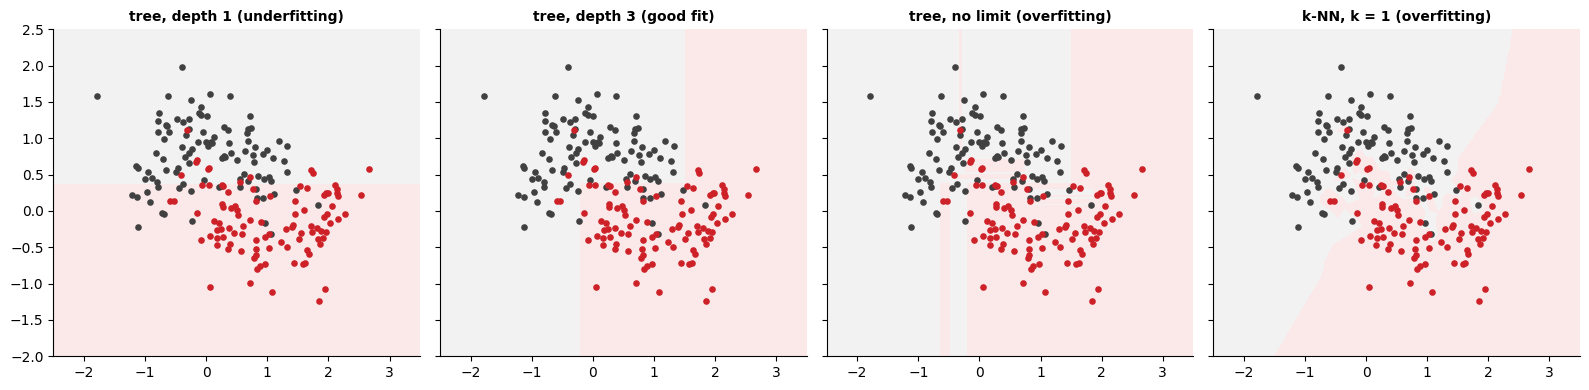

In [20]:
#Decision Boundaries: Underfitting, Good Fit and Overfitting
gx, gy = np.meshgrid(np.linspace(-2.5, 3.5, 250), np.linspace(-2, 2.5, 250))

def plot_boundary(model, ax, title):
    model.fit(Xm_tr, ym_tr)
    z = model.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, z, levels=[-0.5, 0.5, 1.5], colors=["#F2F2F2", "#FBE9EA"])
    ax.scatter(*Xm_tr[ym_tr == 0].T, s=14, color=DARK); ax.scatter(*Xm_tr[ym_tr == 1].T, s=14, color=RED)
    ax.set_title(title, fontsize=10); ax.grid(False)

models = [("tree, depth 1 (underfitting)", DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)),
          ("tree, depth 3 (good fit)", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)),
          ("tree, no limit (overfitting)", DecisionTreeClassifier(random_state=RANDOM_STATE)),
          ("k-NN, k = 1 (overfitting)", KNeighborsClassifier(n_neighbors=1))]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
for ax, (title, model) in zip(axes, models):
    plot_boundary(model, ax, title)
plt.tight_layout(); plt.show()

### **9. How to Combat Overfitting**

| Strategy | Idea |
|---|---|
| **More data** | less room to memorise noise |
| **Regularisation** | penalise large coefficients (L1, L2) |
| **Simpler model / ensembles** | fewer parameters, pruning, averaging many models |
| **Fewer attributes** | feature selection, dimensionality reduction |
| **Early stopping** | stop iterative training at the validation minimum |
| **Cross-validation** | choose the complexity without touching the test set |

#### **More Data**

The same degree-15 polynomial trained with more and more samples:

,training samples,train MSE,test MSE
0,30,0.046,0.194
1,60,0.051,0.117
2,120,0.069,0.102
3,300,0.073,0.104
4,1000,0.092,0.098


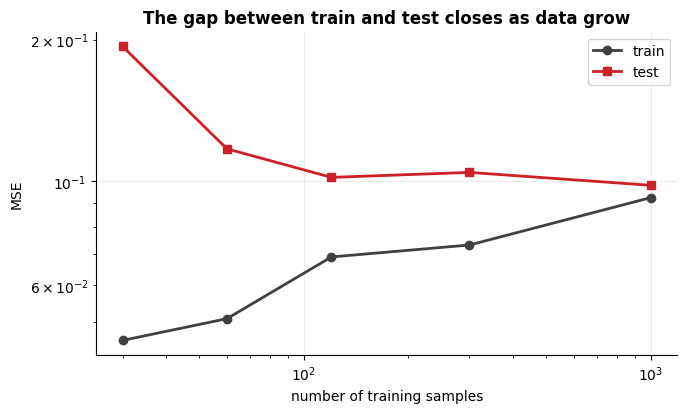

In [21]:
#Degree-15 Polynomial with More Training Samples
rows = []
for n in [30, 60, 120, 300, 1000]:
    Xn, yn = make_data(n, seed=7)
    m = poly_model(15).fit(Xn, yn)
    rows.append((n, mean_squared_error(yn, m.predict(Xn)), mean_squared_error(y_te, m.predict(X_te))))
more_data = pd.DataFrame(rows, columns=["training samples", "train MSE", "test MSE"])
display(more_data.round(3))

plt.figure()
plt.plot(more_data["training samples"], more_data["train MSE"], marker="o", color=DARK, lw=2, label="train")
plt.plot(more_data["training samples"], more_data["test MSE"], marker="s", color=RED, lw=2, label="test")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("number of training samples"); plt.ylabel("MSE"); plt.legend()
plt.title("The gap between train and test closes as data grow")
plt.show()

#### **Regularisation (Ridge and Lasso)**

Penalise large coefficients: **Ridge (L2)** adds $\alpha \sum \beta_j^2$; **Lasso (L1)** adds $\alpha \sum \lvert \beta_j \rvert$ and can **zero** coefficients. The strength $\alpha$ sets the trade-off.

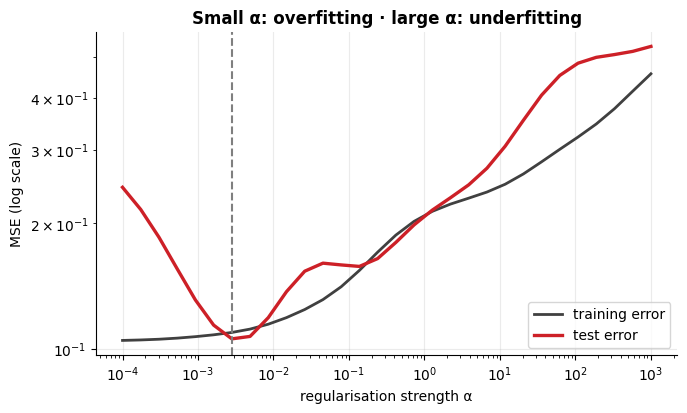

degree 15 without regularisation: test MSE = 65.637
degree 15 with Ridge (α = 0.00281): test MSE = 0.106


In [22]:
#Ridge: Training and Test Error by Regularisation Strength
from sklearn.linear_model import Ridge, Lasso

alphas = np.logspace(-4, 3, 30)
tr_r, te_r = [], []
for a in alphas:
    e_tr_, e_te_ = errors(poly_model(15, Ridge(alpha=a)).fit(X_tr, y_tr))
    tr_r.append(e_tr_); te_r.append(e_te_)
best_alpha = alphas[int(np.argmin(te_r))]

plt.figure()
plt.plot(alphas, tr_r, color=DARK, lw=2, label="training error")
plt.plot(alphas, te_r, color=RED, lw=2.4, label="test error")
plt.axvline(best_alpha, color=GRAY, ls="--")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("regularisation strength α"); plt.ylabel("MSE (log scale)"); plt.legend()
plt.title("Small α: overfitting · large α: underfitting")
plt.show()
print(f"degree 15 without regularisation: test MSE = {errors(poly_model(15).fit(X_tr, y_tr))[1]:.3f}")
print(f"degree 15 with Ridge (α = {best_alpha:.3g}): test MSE = {min(te_r):.3f}")

,model,largest |coefficient|,zero coefficients,train MSE,test MSE
0,no regularisation,1.445e+09,0,0.077,65.637
1,Ridge (α = 0.0028),4.987e+00,0,0.109,0.106
2,Lasso (α = 0.0003),6.624e+00,9,0.113,0.116


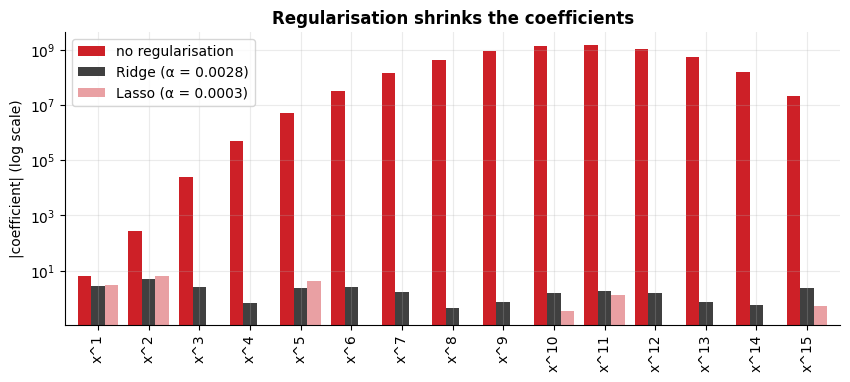

In [23]:
#Coefficients: No Regularisation vs Ridge vs Lasso ( Degree 15 )
models = {"no regularisation": poly_model(15),
          f"Ridge (α = {best_alpha:.2g})": poly_model(15, Ridge(alpha=best_alpha)),
          "Lasso (α = 0.0003)": poly_model(15, Lasso(alpha=0.0003, max_iter=500000))}

rows, coefs = [], {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    c = m[-1].coef_
    coefs[name] = np.abs(c)
    rows.append((name, np.abs(c).max(), int((c == 0).sum()), *errors(m)))
display(pd.DataFrame(rows, columns=["model", "largest |coefficient|", "zero coefficients", "train MSE", "test MSE"]).round(3))

pd.DataFrame(coefs, index=[f"x^{i}" for i in range(1, 16)]).plot.bar(figsize=(10, 3.8), logy=True, width=0.8, color=[RED, DARK, SOFT])
plt.ylabel("|coefficient| (log scale)"); plt.title("Regularisation shrinks the coefficients")
plt.show()

#### **Simpler Model and Ensembles**

Limiting the tree (`min_samples_leaf`) or **averaging many trees** (Random Forest) reduces the variance:

In [24]:
#Single Tree vs Pruned Tree vs Random Forest ( Moons Dataset )
from sklearn.ensemble import RandomForestClassifier

candidates = {"tree (no limit)":            DecisionTreeClassifier(random_state=RANDOM_STATE),
              "tree (min_samples_leaf=10)": DecisionTreeClassifier(min_samples_leaf=10, random_state=RANDOM_STATE),
              "random forest (200 trees)":  RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)}
rows = []
for name, m in candidates.items():
    m.fit(Xm_tr, ym_tr)
    rows.append((name, m.score(Xm_tr, ym_tr), m.score(Xm_te, ym_te)))
pd.DataFrame(rows, columns=["model", "train accuracy", "test accuracy"]).round(3)

,model,train accuracy,test accuracy
0,tree (no limit),1.0,0.79
1,tree (min_samples_leaf=10),0.9,0.79
2,random forest (200 trees),1.0,0.83


Pruning **narrows the gap** (training accuracy 1.00 → 0.90); averaging many trees also **improves the test accuracy**.

#### **Fewer Attributes**

Few samples and many attributes is a classic overfitting setting: 150 samples, **200 attributes, only 8 informative**.

,model,train accuracy,validation accuracy,gap
0,logistic regression (weak regularisation),1.000,0.640,0.360
1,logistic regression (strong regularisation),0.982,0.680,0.302
2,SelectKBest (10) + logistic regression,0.880,0.760,0.120
3,PCA (10) + logistic regression,0.725,0.587,0.138


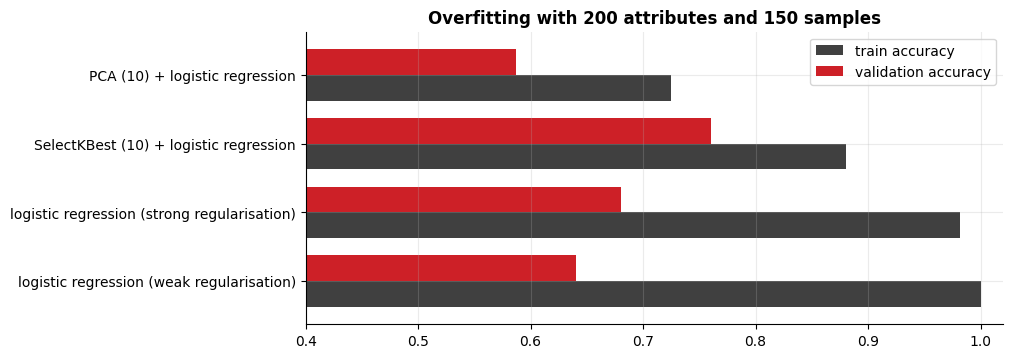

In [25]:
#Many Attributes, Few Samples ( Regularisation, Feature Selection and PCA )
from sklearn.datasets import make_classification
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

Xh, yh = make_classification(n_samples=150, n_features=200, n_informative=8, n_redundant=0, class_sep=1.0, random_state=1)
cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "logistic regression (weak regularisation)":   make_pipeline(StandardScaler(), LogisticRegression(C=1e6, max_iter=10000)),
    "logistic regression (strong regularisation)": make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=10000)),
    "SelectKBest (10) + logistic regression":      make_pipeline(StandardScaler(), SelectKBest(f_classif, k=10), LogisticRegression(max_iter=10000)),
    "PCA (10) + logistic regression":              make_pipeline(StandardScaler(), PCA(n_components=10), LogisticRegression(max_iter=10000)),
}
rows = []
for name, pipe in candidates.items():
    r = cross_validate(pipe, Xh, yh, cv=cv5, return_train_score=True)
    rows.append((name, r["train_score"].mean(), r["test_score"].mean()))
overfit = pd.DataFrame(rows, columns=["model", "train accuracy", "validation accuracy"])
overfit["gap"] = overfit["train accuracy"] - overfit["validation accuracy"]
display(overfit.round(3))

overfit.set_index("model")[["train accuracy", "validation accuracy"]].plot.barh(color=[DARK, RED], figsize=(9, 3.8), width=0.75)
plt.xlim(0.4, 1.02); plt.ylabel(""); plt.title("Overfitting with 200 attributes and 150 samples")
plt.show()

* The weakly regularised model has **100 % training accuracy** but a low validation accuracy
* **Supervised selection** (`SelectKBest`) gives the **best validation accuracy**
* **PCA** shrinks the gap but does **not** help: it keeps the directions of largest *variance*, and here most of it is noise

#### **Early Stopping**

Iterative models keep reducing the **training** error, but the **test** error eventually turns up. Stop at the **validation minimum**:

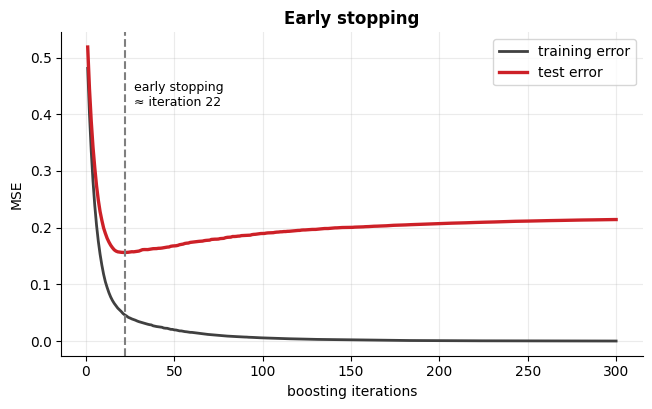

best iteration: 22 (test MSE 0.156) | after 300 iterations: test MSE 0.214, train MSE 0.0001


In [26]:
#Early Stopping with Gradient Boosting ( 300 Iterations )
from sklearn.ensemble import GradientBoostingRegressor

Xb_tr, yb_tr = make_data(60, seed=0)
Xb_te, yb_te = make_data(400, seed=1)
gbr = GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE).fit(Xb_tr, yb_tr)

train_curve = [mean_squared_error(yb_tr, p) for p in gbr.staged_predict(Xb_tr)]
test_curve = [mean_squared_error(yb_te, p) for p in gbr.staged_predict(Xb_te)]
best_iter = int(np.argmin(test_curve)) + 1

plt.figure()
plt.plot(range(1, 301), train_curve, color=DARK, lw=2, label="training error")
plt.plot(range(1, 301), test_curve, color=RED, lw=2.4, label="test error")
plt.axvline(best_iter, color=GRAY, ls="--"); plt.text(best_iter + 5, max(test_curve) * 0.8, f"early stopping\n≈ iteration {best_iter}", fontsize=9)
plt.xlabel("boosting iterations"); plt.ylabel("MSE"); plt.legend(); plt.title("Early stopping")
plt.show()
print(f"best iteration: {best_iter} (test MSE {min(test_curve):.3f}) | after 300 iterations: test MSE {test_curve[-1]:.3f}, train MSE {train_curve[-1]:.4f}")

#### **Cross-Validation to Choose the Hyperparameters**

`GridSearchCV` picks the **degree** and **α** using only the training data; the test set is used **once** at the end.

In [27]:
#Choose Degree and Regularisation with Cross-Validation ( Test Set Used Once )
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(
    make_pipeline(PolynomialFeatures(include_bias=False), StandardScaler(), Ridge()),
    {"polynomialfeatures__degree": [1, 2, 3, 4, 6, 8, 10, 15], "ridge__alpha": [0.01, 0.1, 1, 10]},
    cv=cv, scoring="neg_mean_squared_error").fit(X_tr, y_tr)

print("best parameters   :", search.best_params_)
print(f"cross-validated MSE: {-search.best_score_:.3f}")
print(f"test MSE (used once): {mean_squared_error(y_te, search.predict(X_te)):.3f}")

best parameters   : {'polynomialfeatures__degree': 8, 'ridge__alpha': 0.01}
cross-validated MSE: 0.174
test MSE (used once): 0.118


### **10. How to Combat Underfitting**

| Strategy | Idea |
|---|---|
| **More flexible model** | more parameters / higher degree / deeper model |
| **Better attributes** | feature engineering: give the model the missing information |
| **Less regularisation** | let the model fit the training data more closely |
| **Train longer** | more iterations for iterative algorithms |

#### **Better Attributes**

A line cannot capture a **quadratic** relationship, but adding the feature $x^2$ fixes it **keeping a linear model**:

linear model on x       : test R² = -0.014   (underfitting)
linear model on [x, x²] : test R² = 0.917   (the new attribute fixes it)


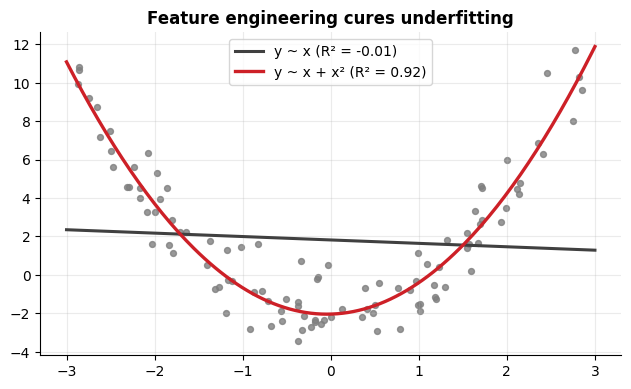

In [28]:
#Feature Engineering Cures Underfitting ( Adding x² )
rng = np.random.default_rng(RANDOM_STATE)
x = rng.uniform(-3, 3, 150)
y_quad = 1.5 * x ** 2 - 2 + rng.normal(0, 1.2, 150)
Xq_tr, Xq_te, yq_tr, yq_te = train_test_split(x.reshape(-1, 1), y_quad, test_size=0.3, random_state=RANDOM_STATE)

line_q = LinearRegression().fit(Xq_tr, yq_tr)
with_square = LinearRegression().fit(np.c_[Xq_tr, Xq_tr ** 2], yq_tr)
r2_line = line_q.score(Xq_te, yq_te)
r2_square = with_square.score(np.c_[Xq_te, Xq_te ** 2], yq_te)
print(f"linear model on x       : test R² = {r2_line:.3f}   (underfitting)")
print(f"linear model on [x, x²] : test R² = {r2_square:.3f}   (the new attribute fixes it)")

xs = np.linspace(-3, 3, 200).reshape(-1, 1)
plt.figure()
plt.scatter(Xq_tr, yq_tr, s=18, color=GRAY, alpha=0.8)
plt.plot(xs, line_q.predict(xs), color=DARK, lw=2.2, label=f"y ~ x (R² = {r2_line:.2f})")
plt.plot(xs, with_square.predict(np.c_[xs, xs ** 2]), color=RED, lw=2.4, label=f"y ~ x + x² (R² = {r2_square:.2f})")
plt.legend(); plt.title("Feature engineering cures underfitting")
plt.show()

#### **Less Regularisation**

Too much regularisation **flattens** the model: a degree-4 polynomial (the right complexity) **underfits** when $\alpha$ is huge.

In [29]:
#Strong Regularisation Causes Underfitting ( Degree 4, Ridge )
rows = []
for a in [10000, 100, 1, 0.01]:
    rows.append((a, *errors(poly_model(4, Ridge(alpha=a)).fit(X_tr, y_tr))))
pd.DataFrame(rows, columns=["alpha", "train MSE", "test MSE"]).round(3)

,alpha,train MSE,test MSE
0,10000.00,0.575,0.591
1,100.00,0.328,0.397
2,1.00,0.240,0.326
3,0.01,0.125,0.114


#### **Train Longer**

With **few iterations** the boosting model is still too simple: **both** errors are high (underfitting).

In [30]:
#Boosting Errors at Selected Iterations ( Underfitting → Good Fit → Overfitting )
its = [1, 5, best_iter, 100, 300]
iters = pd.DataFrame({"iterations": its, "train MSE": [train_curve[i - 1] for i in its], "test MSE": [test_curve[i - 1] for i in its],
                      "diagnosis": ["underfitting", "underfitting", "best (early stopping)", "overfitting", "overfitting"]})
with pd.option_context("display.float_format", "{:.4f}".format):
    display(iters)

,iterations,train MSE,test MSE,diagnosis
0,1,0.4810,0.5186,underfitting
1,5,0.2392,0.3056,underfitting
2,22,0.0461,0.1562,best (early stopping)
3,100,0.0057,0.1897,overfitting
4,300,0.0001,0.2143,overfitting


### **11. Summary**

| Symptom | Diagnosis | What to do |
|---|---|---|
| Training error **high**, test error **high** | **Underfitting** (high bias) | more flexible model · better attributes · less regularisation · train longer |
| Training error **low**, test error **much higher** | **Overfitting** (high variance) | more data · regularisation · simpler model · fewer attributes · early stopping · ensembles |
| Both **low** and close | **Good fit** | evaluate **once** on the test set |

A simple **rule of thumb**, comparing with a baseline that always predicts the mean:

In [31]:
#Rule-of-Thumb Diagnosis ( Compare with the Mean Baseline )
from sklearn.dummy import DummyRegressor

baseline = mean_squared_error(y_te, DummyRegressor().fit(X_tr, y_tr).predict(X_te))

def diagnose(model):
    e_tr, e_te = errors(model)
    if e_te > 2 * e_tr:
        return "overfitting"
    if e_tr > 0.3 * baseline:
        return "underfitting"
    return "good fit"

rows = []
for d in [1, 2, 4, 8, 15]:
    e_tr, e_te = errors(poly_model(d).fit(X_tr, y_tr))
    rows.append((d, e_tr, e_te, diagnose(poly_model(d).fit(X_tr, y_tr))))
display(pd.DataFrame(rows, columns=["degree", "train MSE", "test MSE", "diagnosis"]).round(3))
print(f"baseline (always the mean): test MSE = {baseline:.3f}")

,degree,train MSE,test MSE,diagnosis
0,1,0.280,0.314,underfitting
1,2,0.240,0.366,underfitting
2,4,0.117,0.112,good fit
3,8,0.099,0.266,overfitting
4,15,0.077,65.637,overfitting


baseline (always the mean): test MSE = 0.597
